# What does a SHAP-guided cut actually look like?

Notebook 02 established, in aggregate over 100 reviews, that cutting the text
SHAP calls unimportant barely moves the model. Aggregates are the right
evidence but the wrong intuition, so this notebook walks one review through the
full path: the text, its word attributions, the exact reduced texts that
survive cuts at the 20, 40 and 60 percent thresholds for chunk sizes 1, 4 and 8
under the `absolute_sum` combination, and the model's prediction on every one
of them.

Everything reuses the machinery notebook 02 measured with. The masks come from
`select_kept_words`, the same function the sufficiency sweep cuts through, so
the pictures below show precisely the texts behind those aggregate numbers
rather than a reimplementation of them.

A threshold follows notebook 02's vocabulary: 40 means the 40th percentile of
this review's own chunk importances, so roughly 40 percent of the text gets
cut. The least important chunks go first, which is the sufficiency direction,
the one where a faithful ranking predicts the output should barely move.
The comprehensiveness mirror, cutting the most important chunks instead, is a
single flag on `select_kept_words` and is deliberately not duplicated here.

## Configuration

In [1]:
from pathlib import Path

from textfaith.faithfulness import ABSOLUTE_SUM

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHECKPOINT_DIRECTORY = PROJECT_ROOT / "artifacts" / "sample_2000"

OBSERVATION_COUNT = 100
RANDOM_SEED = 42
ATTRIBUTIONS_PATH = CHECKPOINT_DIRECTORY / f"word_attributions_{OBSERVATION_COUNT}.joblib"

CUT_PERCENTILES = [20, 40, 60]
CHUNK_SIZES = [1, 4, 8]
COMBINATION = ABSOLUTE_SUM

MINIMUM_WORD_COUNT = 60
MINIMUM_CONFIDENCE = 0.80
CLASS_NAMES = {0: "negative", 1: "positive"}

print(f"Checkpoint: {CHECKPOINT_DIRECTORY}")
print(f"Cut thresholds: {CUT_PERCENTILES}")
print(f"Chunk sizes: {CHUNK_SIZES}")
print(f"Combination: {COMBINATION}")

Checkpoint: /home/user/projects/shapley/artifacts/sample_2000
Cut thresholds: [20, 40, 60]
Chunk sizes: [1, 4, 8]
Combination: absolute_sum


/home/user/projects/shapley/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the classifier and the cached attributions

The attribution cache is positional, one array per review in sample order, so
the sample must be drawn exactly as notebook 02 drew it, same seed, same
stratification. The alignment assertion below catches every way that could
silently drift, because an attribution array only fits the review it was
computed for.

Attributions are never recomputed here. If the cache is missing, run
notebook 02 first, it owns the 20 minute SHAP computation and this notebook
stays cheap.

In [2]:
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split

from textfaith.checkpoint import load_predictor
from textfaith.faithfulness import build_word_masker

predict_probabilities, tokenizer = load_predictor(CHECKPOINT_DIRECTORY)

test_reviews = pd.read_parquet(CHECKPOINT_DIRECTORY / "test.parquet")
sampled_reviews, _ = train_test_split(
    test_reviews,
    train_size=OBSERVATION_COUNT,
    random_state=RANDOM_SEED,
    stratify=test_reviews["label"],
)
texts = sampled_reviews["text"].tolist()
labels = sampled_reviews["label"].tolist()

masker = build_word_masker()

assert ATTRIBUTIONS_PATH.exists(), "No attribution cache, run notebooks/02_faithfulness.ipynb first"
word_attributions = joblib.load(ATTRIBUTIONS_PATH)

for text, attribution in zip(texts, word_attributions):
    assert len(attribution) == len(masker.data_transform(text)[0]), (
        "Cached attributions do not align with this sample, rebuild the cache"
    )

print(f"Loaded predictor and {len(word_attributions)} cached attribution arrays")
print("Every attribution array aligns with the masker's word split of its review")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15359.79it/s]

Loaded predictor and 100 cached attribution arrays
Every attribution array aligns with the masker's word split of its review


## Choose the example review

A hand picked index would be fragile against any cache rebuild and slightly
dishonest besides, so the choice is a stated criterion instead: correctly
predicted, with probability at least 0.80, and at least 60 words long so a
chunk size of 8 still yields around eight chunks to rank. The confidence bar
looks low but is not, the MLP head is softly calibrated and never exceeds 0.87
on this sample. Among the qualifying reviews the shortest one is taken, purely
so the whole text stays legible inside a figure.

In [3]:
import numpy as np

all_probabilities = predict_probabilities(texts)
predicted_classes = all_probabilities.argmax(axis=1)
confidences = all_probabilities.max(axis=1)
word_counts = np.array([len(attribution) for attribution in word_attributions])

candidates = (
    (predicted_classes == np.array(labels))
    & (confidences >= MINIMUM_CONFIDENCE)
    & (word_counts >= MINIMUM_WORD_COUNT)
)
assert candidates.any(), "No review satisfies the selection criterion, relax the thresholds"

candidate_indices = np.flatnonzero(candidates)
chosen_index = int(candidate_indices[np.argmin(word_counts[candidates])])

chosen_text = texts[chosen_index]
chosen_attribution = word_attributions[chosen_index]
chosen_words = masker.data_transform(chosen_text)[0]
predicted_class = int(predicted_classes[chosen_index])
predicted_class_name = CLASS_NAMES[predicted_class]
uncut_probability = float(all_probabilities[chosen_index, predicted_class])

print(f"Candidates satisfying the criterion: {candidates.sum()} of {len(texts)}")
print(f"Chosen review: sample position {chosen_index}, {len(chosen_words)} words")
print(
    f"True label {CLASS_NAMES[labels[chosen_index]]}, predicted {predicted_class_name} "
    f"with probability {uncut_probability:.4f}"
)
print()
print(chosen_text)

Candidates satisfying the criterion: 7 of 100
Chosen review: sample position 76, 64 words
True label positive, predicted positive with probability 0.8526

An enthralling, wonderful look at the films that inspired the excellent Martin Scorsese. Many of the films he speaks of are easy to relate to his works, particularly the earlier ones, the silent era. Very enjoyable despite being a bit long, I found this to be one of the best documentaries on film yet. Required viewing if you admire Martin Scorsese and his work.


## The review under its attributions

`shap.plots.text` would be the obvious renderer, but the cache holds plain
arrays for the predicted class without base values, and rebuilding an
`Explanation` around a fabricated base value would misrepresent what was
computed. A direct matplotlib rendering shows exactly the cached numbers and
survives every viewer that strips HTML from notebook outputs.

C0 marks words pushing toward the predicted class, C1 words pushing against
it, and intensity is magnitude relative to the strongest word of this review.
The same word renderer draws the cut grid later, with removed words in gray,
so the two figures stay directly comparable.

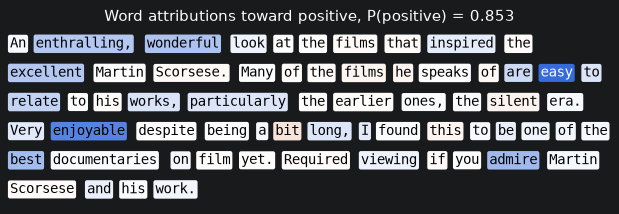

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize

MONOSPACE_CHARACTER_WIDTH_EM = 0.602
LINE_HEIGHT_EM = 1.9

attribution_colormap = LinearSegmentedColormap.from_list("attribution", ["C1", "white", "C0"])


def wrap_words(words, characters_per_line):
    """Assign each word a character column and a line, wrapping at the line width."""
    positions = []
    column = 0
    line = 0
    for word in words:
        stripped_word = word.strip()
        if column > 0 and column + len(stripped_word) > characters_per_line:
            column = 0
            line += 1
        positions.append((column, line))
        column += len(stripped_word) + 1
    return positions


def render_words(axis, words, attribution, cut_mask=None, characters_per_line=70, fontsize=10):
    """Draw a review on a character grid, coloring kept words and graying cut ones."""
    maximum_magnitude = np.abs(attribution).max()
    normalize = Normalize(-maximum_magnitude, maximum_magnitude)
    positions = wrap_words(words, characters_per_line)
    for index, (word, value) in enumerate(zip(words, attribution)):
        column, line = positions[index]
        stripped_word = word.strip()
        if cut_mask is not None and cut_mask[index]:
            axis.text(
                column, -line, stripped_word, fontsize=fontsize,
                family="monospace", ha="left", va="center", color="0.8",
            )
            continue
        background = attribution_colormap(normalize(value))
        red, green, blue = background[:3]
        luminance = 0.299 * red + 0.587 * green + 0.114 * blue
        axis.text(
            column, -line, stripped_word, fontsize=fontsize,
            family="monospace", ha="left", va="center",
            color="white" if luminance < 0.5 else "black",
            bbox=dict(facecolor=background, edgecolor="none", boxstyle="round,pad=0.15"),
        )
    line_count = positions[-1][1] + 1
    axis.set_xlim(0, characters_per_line)
    axis.set_ylim(-line_count + 0.5, 0.5)
    axis.axis("off")


def word_figure_size(characters_per_line, line_count, fontsize):
    """Figure size in inches that gives one character roughly one data unit."""
    width = characters_per_line * fontsize * MONOSPACE_CHARACTER_WIDTH_EM / 72 * 1.08
    height = (line_count + 1) * fontsize * LINE_HEIGHT_EM / 72
    return width, height


REVIEW_CHARACTERS_PER_LINE = 70
REVIEW_FONTSIZE = 10

review_line_count = wrap_words(chosen_words, REVIEW_CHARACTERS_PER_LINE)[-1][1] + 1
figure_width, figure_height = word_figure_size(
    REVIEW_CHARACTERS_PER_LINE, review_line_count, REVIEW_FONTSIZE
)
figure, axis = plt.subplots(figsize=(figure_width, figure_height + 0.4))
render_words(
    axis, chosen_words, chosen_attribution,
    characters_per_line=REVIEW_CHARACTERS_PER_LINE, fontsize=REVIEW_FONTSIZE,
)
axis.set_title(
    f"Word attributions toward {predicted_class_name}, "
    f"P({predicted_class_name}) = {uncut_probability:.3f}",
    fontsize=11,
)
figure.tight_layout()
plt.show()

## Cut the least important chunks

For every chunk size the review is scored in runs of consecutive words with
`absolute_sum`, and the chunks below each threshold are removed through the
same masker that produced the attributions. All nine variants plus the uncut
original go through a single batched prediction call.

The printed strings are the model's actual inputs. Cut runs collapse into a
literal `...` marker, that is how the masker represents removed text, and the
model sees those markers too. This is worth staring at once: the 60 percent
cuts read like telegrams, yet the predictions barely move.

In [5]:
from textfaith.faithfulness import select_kept_words

variant_keys = [
    (chunk_size, percentile)
    for chunk_size in CHUNK_SIZES
    for percentile in CUT_PERCENTILES
]
kept_masks = {
    (chunk_size, percentile): select_kept_words(
        chosen_attribution, percentile, chunk_size, COMBINATION
    )
    for chunk_size, percentile in variant_keys
}
reduced_texts = {key: masker(kept_masks[key], chosen_text)[0][0] for key in variant_keys}

variant_probabilities = predict_probabilities(
    [chosen_text] + [reduced_texts[key] for key in variant_keys]
)
assert variant_probabilities.shape == (len(variant_keys) + 1, 2)
assert np.allclose(variant_probabilities[0], all_probabilities[chosen_index], atol=1e-5), (
    "Batched prediction disagrees with the earlier full text prediction"
)

kept_word_counts = {key: int(mask.sum()) for key, mask in kept_masks.items()}
for chunk_size in CHUNK_SIZES:
    counts = [kept_word_counts[(chunk_size, percentile)] for percentile in CUT_PERCENTILES]
    assert counts == sorted(counts, reverse=True), "Deeper cuts must keep fewer words"

cut_probabilities = {
    key: float(probabilities[predicted_class])
    for key, probabilities in zip(variant_keys, variant_probabilities[1:])
}

print(f"Uncut: P({predicted_class_name}) = {uncut_probability:.4f}")
print()
for key in variant_keys:
    chunk_size, percentile = key
    print(
        f"chunk {chunk_size} | cut {percentile}% | "
        f"kept {kept_word_counts[key]}/{len(chosen_words)} words | "
        f"P({predicted_class_name}) = {cut_probabilities[key]:.4f}"
    )
    print(f"  {reduced_texts[key]}")
    print()

Uncut: P(positive) = 0.8526

chunk 1 | cut 20% | kept 51/64 words | P(positive) = 0.8446
  An enthralling, wonderful look ...films that inspired the excellent ...Scorsese. ...of the films he ...of are easy to relate ...his works, particularly ...ones, ...silent era. Very enjoyable ...a bit long, I ...this to be one of the best documentaries on film yet. Required viewing if ...admire Martin Scorsese and his work.

chunk 1 | cut 40% | kept 38/64 words | P(positive) = 0.8396
  An enthralling, wonderful look ...films that inspired ...excellent ...films he ...of are easy to relate ...works, particularly ...silent era. Very enjoyable ...a bit long, I ...this to be one of the best ...on ...viewing ...admire Martin ...and ...work.

chunk 1 | cut 60% | kept 27/64 words | P(positive) = 0.8120
  ...enthralling, wonderful look ...inspired ...excellent ...films he ...are easy to relate ...works, particularly ...silent ...Very enjoyable ...bit long, I ...this ...be one ...best ...viewing ...admire .

## Every cut at a glance

Rows are chunk sizes, columns are thresholds, gray words are cut. Reading down
a column shows what chunking changes about the shape of a cut at a fixed
budget: chunk size 1 pecks out scattered single words, chunk size 8 removes
whole contiguous runs. Reading across a row shows the same ranking biting
progressively deeper. The kept word counts differ slightly between rows at the
same threshold because a percentile over 8 chunks is a coarser instrument than
one over 64 words.

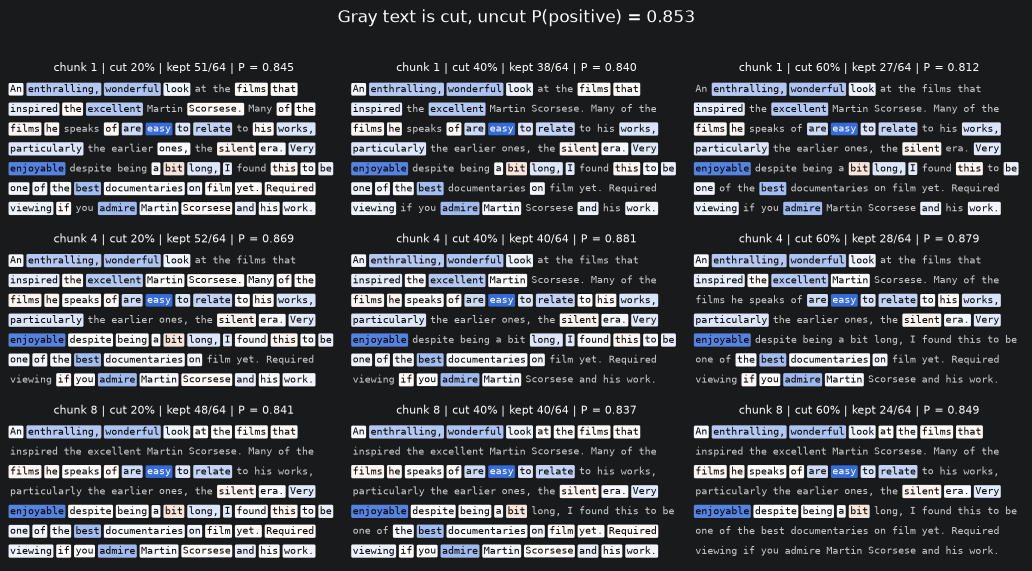

In [6]:
GRID_CHARACTERS_PER_LINE = 55
GRID_FONTSIZE = 7

grid_line_count = wrap_words(chosen_words, GRID_CHARACTERS_PER_LINE)[-1][1] + 1
panel_width, panel_height = word_figure_size(
    GRID_CHARACTERS_PER_LINE, grid_line_count, GRID_FONTSIZE
)
figure, axes = plt.subplots(
    len(CHUNK_SIZES),
    len(CUT_PERCENTILES),
    figsize=(panel_width * len(CUT_PERCENTILES), (panel_height + 0.45) * len(CHUNK_SIZES)),
)
for row, chunk_size in enumerate(CHUNK_SIZES):
    for column, percentile in enumerate(CUT_PERCENTILES):
        key = (chunk_size, percentile)
        axis = axes[row, column]
        render_words(
            axis, chosen_words, chosen_attribution, cut_mask=~kept_masks[key],
            characters_per_line=GRID_CHARACTERS_PER_LINE, fontsize=GRID_FONTSIZE,
        )
        axis.set_title(
            f"chunk {chunk_size} | cut {percentile}% | "
            f"kept {kept_word_counts[key]}/{len(chosen_words)} | "
            f"P = {cut_probabilities[key]:.3f}",
            fontsize=8,
        )
figure.suptitle(
    f"Gray text is cut, uncut P({predicted_class_name}) = {uncut_probability:.3f}",
    fontsize=12,
)
figure.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## Prediction as a function of the cut

The same nine numbers as a curve, in the style of notebook 02, with the uncut
probability as the dashed reference. A faithful ranking predicts flat lines
near the reference, which is what sufficiency being low means for a single
review.

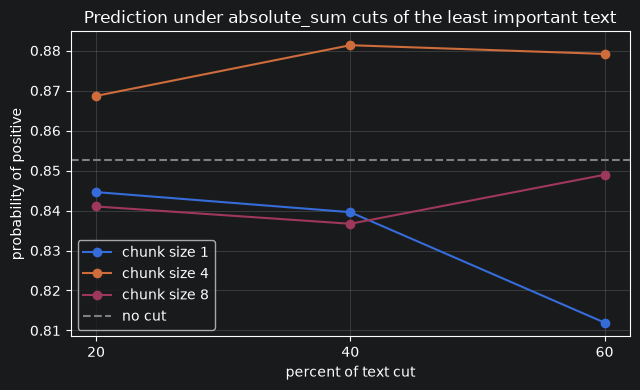

percent_cut      20      40      60
chunk_size                         
1            0.8446  0.8396  0.8120
4            0.8687  0.8813  0.8792
8            0.8410  0.8367  0.8489


In [7]:
chunk_size_colors = dict(zip(CHUNK_SIZES, ["C0", "C1", "C2"]))

figure, axis = plt.subplots(figsize=(6.5, 4.0))
for chunk_size in CHUNK_SIZES:
    axis.plot(
        CUT_PERCENTILES,
        [cut_probabilities[(chunk_size, percentile)] for percentile in CUT_PERCENTILES],
        "-o",
        color=chunk_size_colors[chunk_size],
        label=f"chunk size {chunk_size}",
    )
axis.axhline(uncut_probability, color="0.5", linestyle="--", label="no cut")
axis.set_xticks(CUT_PERCENTILES)
axis.set_xlabel("percent of text cut")
axis.set_ylabel(f"probability of {predicted_class_name}")
axis.set_title(f"Prediction under {COMBINATION} cuts of the least important text")
axis.grid(alpha=0.3)
axis.legend()
figure.tight_layout()
plt.show()

probability_table = pd.DataFrame(
    {
        percentile: [
            cut_probabilities[(chunk_size, percentile)] for chunk_size in CHUNK_SIZES
        ]
        for percentile in CUT_PERCENTILES
    },
    index=pd.Index(CHUNK_SIZES, name="chunk_size"),
).rename_axis(columns="percent_cut")
print(probability_table.round(4).to_string())

## Reading of the result

The prediction never leaves the predicted class, and even after cutting 60
percent of the text it stays within a few hundredths of the uncut probability.
The ranking, not the amount of text, is carrying the prediction, which is
exactly the sufficiency claim notebook 02 verified across 100 reviews.

Two details reward attention. Chunk size 1 drifts furthest at the deepest cut,
because word level cuts shred sentence structure into isolated fragments even
when the removed words individually carried little attribution. And some
chunked cuts land slightly above the uncut baseline: `absolute_sum` removes
the spans whose signed attributions sum to roughly nothing, so a cut can drop
mildly negative text and leave the model marginally more confident than it
was on the full review.

In [8]:
largest_shift = max(
    abs(probability - uncut_probability) for probability in cut_probabilities.values()
)
deepest_cut_probabilities = {
    chunk_size: cut_probabilities[(chunk_size, CUT_PERCENTILES[-1])]
    for chunk_size in CHUNK_SIZES
}
print(
    f"Across all nine cuts P({predicted_class_name}) moved at most "
    f"{largest_shift:.3f} from the uncut {uncut_probability:.3f}."
)
print(
    f"At the {CUT_PERCENTILES[-1]} percent cut the prediction stayed at "
    + ", ".join(
        f"{probability:.3f} (chunk {chunk_size})"
        for chunk_size, probability in deepest_cut_probabilities.items()
    )
    + "."
)
print(
    "SHAP's ranking of this review is sufficient: the text it keeps carries "
    "the prediction, the text it cuts was mostly noise."
)

Across all nine cuts P(positive) moved at most 0.041 from the uncut 0.853.
At the 60 percent cut the prediction stayed at 0.812 (chunk 1), 0.879 (chunk 4), 0.849 (chunk 8).
SHAP's ranking of this review is sufficient: the text it keeps carries the prediction, the text it cuts was mostly noise.
